# 03 · EDA com pontos de interesse (POIs) — Aluguel São Paulo (capital)

**Entradas**
- `data/interim/aluguel_sp_clean.parquet` (notebook 01)
- `data/raw/osm/*_sp.csv` — POIs do OpenStreetMap: escolas, hospitais, farmácias, mercados, polícia, metrô/trem e parques

**Pergunta central:** quanto a proximidade de cada tipo de POI se associa ao preço do aluguel — e quanto disso é só um retrato de "área nobre / central"?
Este notebook descreve; o 04 testa com controles.

**Saída:** `data/interim/aluguel_sp_poi.parquet` — base limpa + features de POI.

### O que muda em relação ao projeto de compra
| Ponto | Compra | Aqui |
|---|---|---|
| Parques | ~7 mil polígonos, a maioria praças | **Parque** (≥ 1 ha) separado de **praça/jardim** |
| Escolas | escola pública × privada | + **ensino superior** separado (faculdades distorciam "escola privada") |
| Metrô | não usado | só **estações em operação**; metrô e trem (CPTM/ViaMobilidade) separados |
| Distância | até o centróide | até a **borda** do polígono, em metros (projeção SIRGAS 2000 / UTM 23S) |
| Medidas | distância + 1 raio | distância, contagens em 500 m e 1 km, e **acessibilidade** (soma com decaimento exponencial) |

### Roteiro
1. Setup e carga
2. Limpeza e categorização dos POIs
3. Cobertura do OSM (viés de mapeamento)
4. Cálculo das features
5. EDA univariada das features
6. R$/m² × distância a cada POI
7. POIs como retrato de "área nobre"
8. Escolas públicas × privadas
9. Metrô e trem
10. Resumo e hipóteses para o 04
11. Salvar

## 1. Setup e carga

In [12]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from shapely import wkt

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

pd.options.display.float_format = "{:,.2f}".format
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid", context="notebook")

COR = "#2a6f97"
CINZA = "#c0c7cf"
CRS_GEO, CRS_M = 4326, 31983          # WGS84 -> SIRGAS 2000 / UTM 23S (metros)
RNG = 42


def achar_raiz(marcador: str = ".git") -> Path:
    p = Path.cwd().resolve()
    for candidato in [p, *p.parents]:
        if (candidato / marcador).exists():
            return candidato
    raise FileNotFoundError(f"Raiz do projeto ({marcador}) não encontrada a partir de {p}")


ROOT = achar_raiz()
OSM = ROOT / "data/raw/osm"
OUT_POI = ROOT / "data/interim/aluguel_sp_poi.parquet"

df = pd.read_parquet(ROOT / "data/interim/aluguel_sp_clean.parquet")
imoveis = gpd.GeoDataFrame(df[["id"]], geometry=gpd.points_from_xy(df["lon"], df["lat"]), crs=CRS_GEO).to_crs(CRS_M)
print(df.shape)

(22213, 96)


## 2. Limpeza e categorização dos POIs

| Categoria | Arquivo | Filtro |
|---|---|---|
| `escola_publica` | escolas_sp | `amenity == school` e `tipo_escola == publica` |
| `escola_privada` | escolas_sp | `amenity == school` e `tipo_escola == privada` |
| `ensino_superior` | escolas_sp | `amenity` em `university`, `college` |
| `hospital` | hospitais_sp | todos |
| `farmacia` | farmacia_sp | todos |
| `supermercado` | mercados_sp | `shop == supermarket` |
| `conveniencia` | mercados_sp | `shop == convenience` |
| `policia` | policia_sp | `amenity == police` (sem fórum e bombeiros) |
| `metro` | metro_sp | `railway` em `station`, `stop` e estação de metrô; sem obras/planejadas/entradas |
| `trem` | metro_sp | idem, estações de trem (CPTM / ViaMobilidade) |
| `parque` | parques_sp | `leisure == park` com área ≥ 1 ha |
| `praca` | parques_sp | demais `park` / `garden` (< 1 ha) |

Geometrias são mantidas (pontos e polígonos). Duplicatas (mesmo POI mapeado como ponto e polígono) são removidas por nome + proximidade (< 150 m).

In [13]:
def ler_osm(arquivo: str) -> gpd.GeoDataFrame:
    d = pd.read_csv(OSM / arquivo, low_memory=False)
    return gpd.GeoDataFrame(d, geometry=d["geometry"].map(wkt.loads), crs=CRS_GEO).to_crs(CRS_M)


def deduplicar(g: gpd.GeoDataFrame, dist_m: float = 150) -> gpd.GeoDataFrame:
    """Remove o mesmo POI mapeado duas vezes: mesmo nome e centróides a menos de dist_m."""
    g = g.copy()
    g["_nome"] = g["name"].fillna("").str.lower().str.strip()
    g["_cx"] = (g.geometry.centroid.x // dist_m).astype(int)
    g["_cy"] = (g.geometry.centroid.y // dist_m).astype(int)
    com_nome = g["_nome"] != ""
    dup = com_nome & g.duplicated(subset=["_nome", "_cx", "_cy"])
    return g.loc[~dup].drop(columns=["_nome", "_cx", "_cy"])


escolas = ler_osm("escolas_sp.csv")
mercados = ler_osm("mercados_sp.csv")
transporte = ler_osm("metro_sp.csv")
verdes = ler_osm("parques_sp.csv")
policia = ler_osm("policia_sp.csv")

verdes["area_ha"] = verdes.area / 1e4
eh_park = verdes["leisure"].astype(str).str.startswith("park")
estacao = transporte["railway"].isin(["station", "stop"])
eh_metro = (transporte["station"] == "subway") | (transporte["subway"] == "yes")

POIS = {
    "escola_publica": escolas[(escolas["amenity"] == "school") & (escolas["tipo_escola"] == "publica")],
    "escola_privada": escolas[(escolas["amenity"] == "school") & (escolas["tipo_escola"] == "privada")],
    "ensino_superior": escolas[escolas["amenity"].isin(["university", "college"])],
    "hospital": ler_osm("hospitais_sp.csv"),
    "farmacia": ler_osm("farmacia_sp.csv"),
    "supermercado": mercados[mercados["shop"] == "supermarket"],
    "conveniencia": mercados[mercados["shop"] == "convenience"],
    "policia": policia[policia["amenity"] == "police"],
    "metro": transporte[estacao & eh_metro],
    "trem": transporte[estacao & ~eh_metro & (transporte["train"] == "yes")],
    "parque": verdes[eh_park & (verdes["area_ha"] >= 1)],
    "praca": verdes[(eh_park & (verdes["area_ha"] < 1)) | (verdes["leisure"] == "garden")],
}

resumo_pois = []
for nome in POIS:
    antes = len(POIS[nome])
    POIS[nome] = deduplicar(POIS[nome])[["name", "geometry"]].reset_index(drop=True)
    tipos_geom = POIS[nome].geom_type.value_counts()
    resumo_pois.append({"categoria": nome, "bruto": antes, "após dedup": len(POIS[nome]),
                        "% polígono": tipos_geom.filter(like="Polygon").sum() / len(POIS[nome])})
CATS = list(POIS)
pd.DataFrame(resumo_pois).set_index("categoria")

,bruto,após dedup,% polígono
categoria,,,
escola_publica,652,649,0.90
escola_privada,889,883,0.77
ensino_superior,296,292,0.79
hospital,234,233,0.85
farmacia,926,913,0.51
supermercado,840,827,0.57
conveniencia,666,659,0.37
policia,370,367,0.55
metro,93,87,0.11


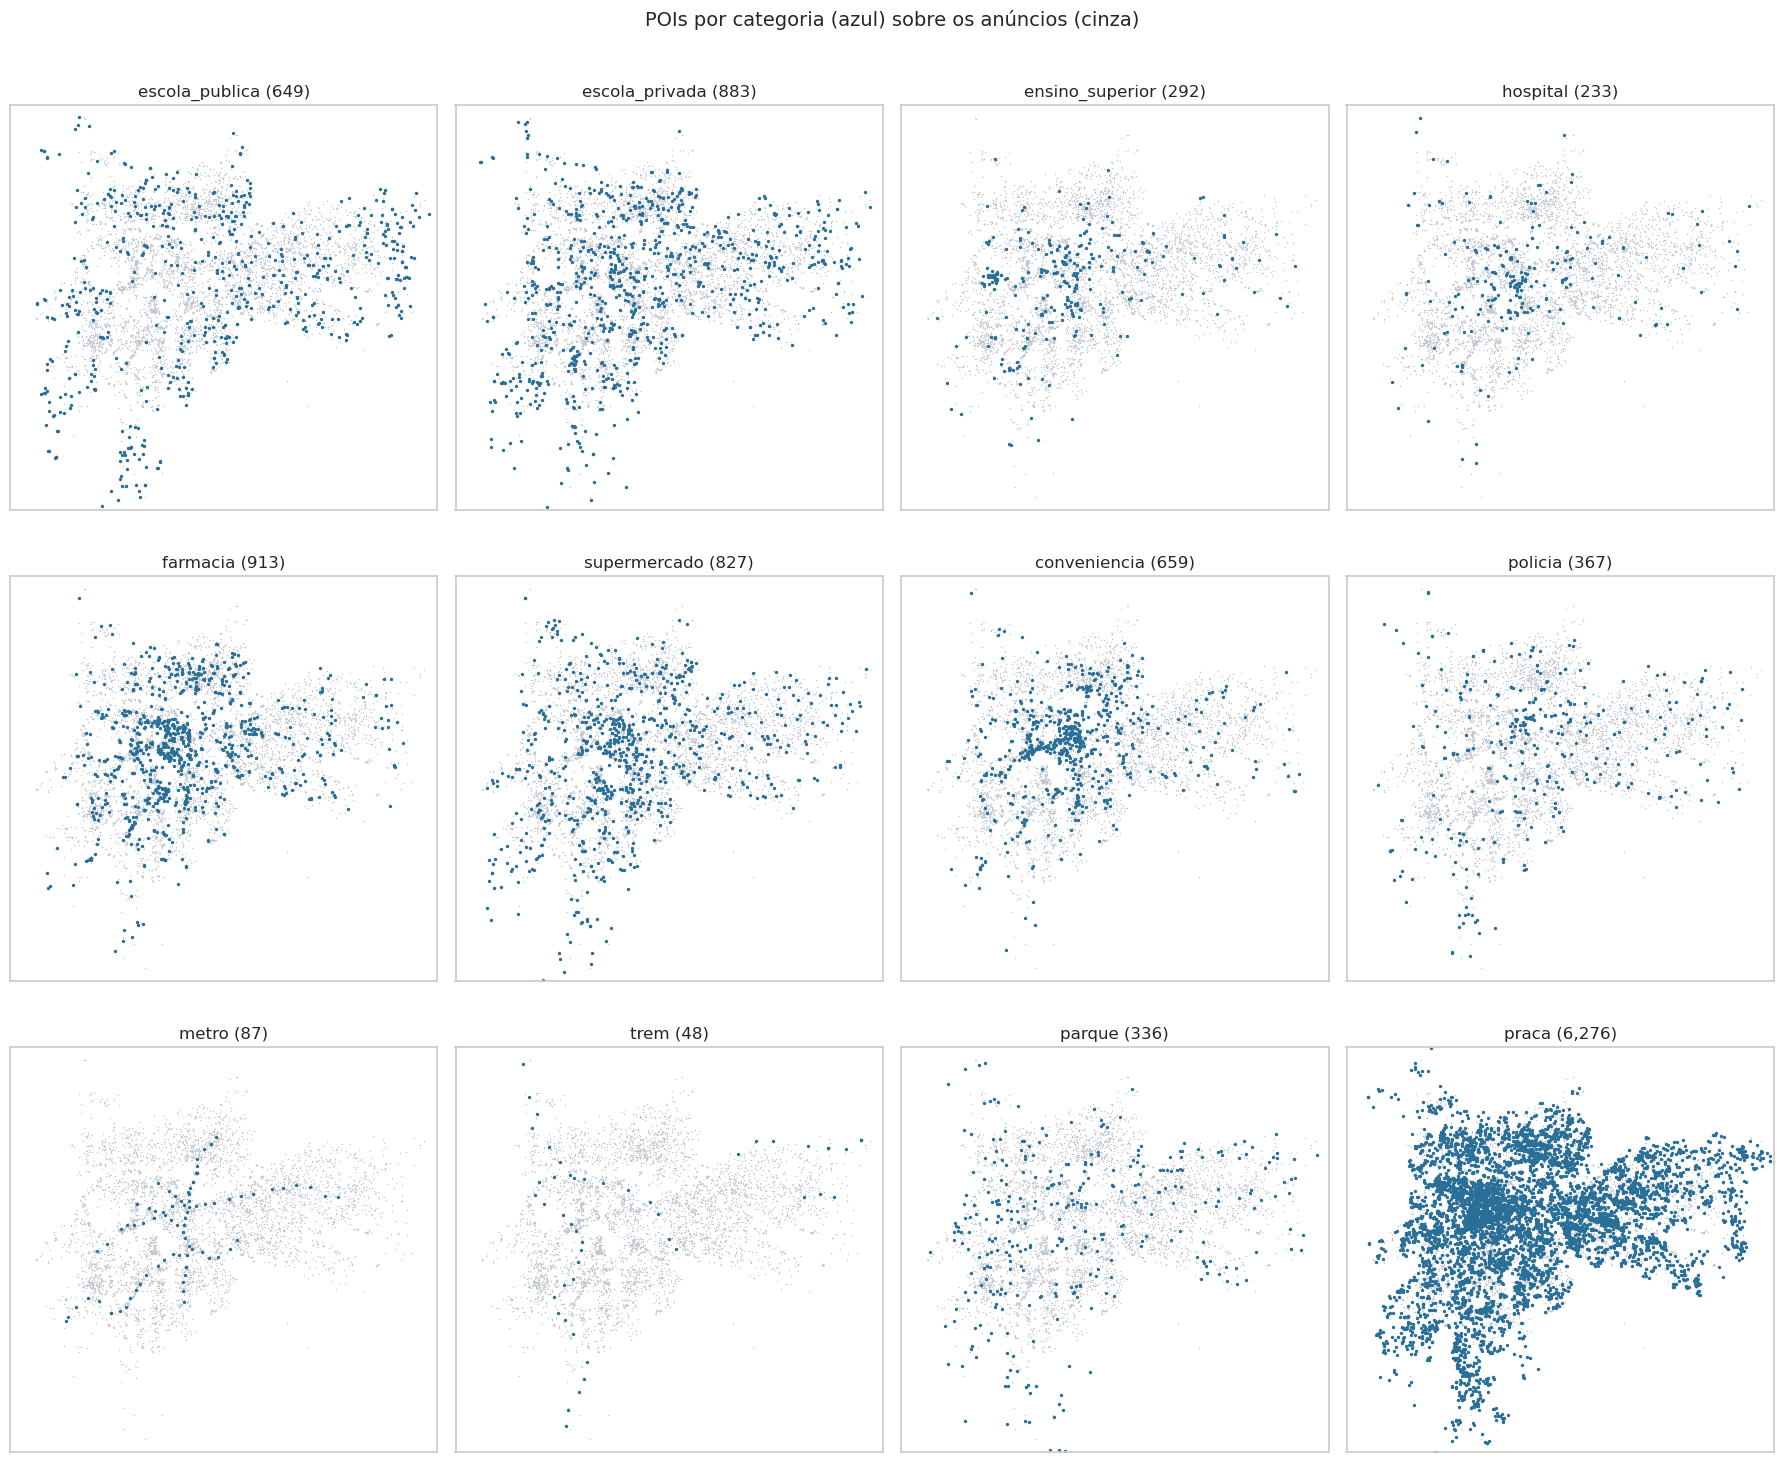

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(18, 15), sharex=True, sharey=True)
fundo = imoveis.sample(6000, random_state=RNG)
xmin, ymin, xmax, ymax = imoveis.total_bounds
for ax, nome in zip(axes.flat, CATS):
    ax.scatter(fundo.geometry.x, fundo.geometry.y, s=1, color=CINZA, linewidths=0)
    c = POIS[nome].geometry.centroid
    ax.scatter(c.x, c.y, s=6, color=COR, linewidths=0)
    ax.set_title(f"{nome} ({len(POIS[nome]):,})")
    ax.set_xlim(xmin - 1500, xmax + 1500)
    ax.set_ylim(ymin - 1500, ymax + 1500)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("POIs por categoria (azul) sobre os anúncios (cinza)", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

## 3. Cobertura do OSM (viés de mapeamento)

O OpenStreetMap é colaborativo: áreas centrais e ricas tendem a ser **mais bem mapeadas** que a periferia.
Se isso acontece, "muitos POIs por perto" mede em parte **esforço de mapeamento**, não oferta real de serviços — e qualquer efeito de POI fica confundido com renda.

Duas checagens:
1. **Ordem de grandeza:** São Paulo tem alguns milhares de escolas públicas (redes municipal e estadual). Quantas o OSM tem?
2. **Densidade de POIs por região × R$/m²** da região.

Escolas públicas no OSM: 649  |  privadas: 883
Na rede real há milhares de escolas públicas na capital → o OSM cobre só uma fração delas.



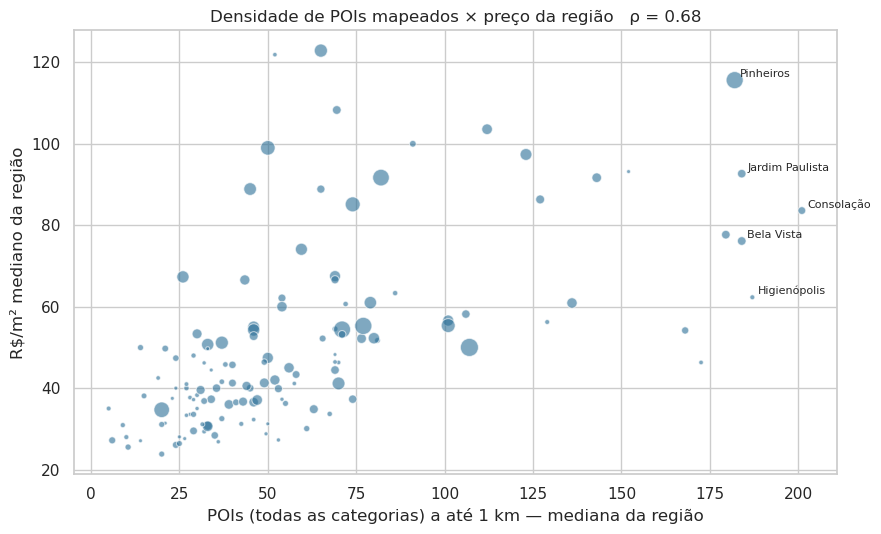

In [15]:
print(f"Escolas públicas no OSM: {len(POIS['escola_publica']):,}  |  privadas: {len(POIS['escola_privada']):,}")
print("Na rede real há milhares de escolas públicas na capital → o OSM cobre só uma fração delas.\n")

# Densidade de POIs ao redor de cada anúncio (1 km) agregada por região
todos = pd.concat([g.assign(cat=n) for n, g in POIS.items()], ignore_index=True)
todos = gpd.GeoDataFrame(todos, geometry="geometry", crs=CRS_M)
idx_im, _ = todos.sindex.query(imoveis.geometry, predicate="dwithin", distance=1000)
df["n_pois_1km"] = np.bincount(idx_im, minlength=len(imoveis))

reg = (df.groupby("regionName").agg(n=("id", "size"), pois_1km=("n_pois_1km", "median"), rent_m2=("rent_m2", "median"))
       .query("n >= 30"))
rho, p = stats.spearmanr(reg["pois_1km"], reg["rent_m2"])

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(reg["pois_1km"], reg["rent_m2"], s=reg["n"] / 4, color=COR, alpha=0.6, edgecolor="white", linewidth=0.8)
for nome, r in reg.nlargest(5, "pois_1km").iterrows():
    ax.annotate(nome, (r["pois_1km"], r["rent_m2"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("POIs (todas as categorias) a até 1 km — mediana da região")
ax.set_ylabel("R$/m² mediano da região")
ax.set_title(f"Densidade de POIs mapeados × preço da região   ρ = {rho:.2f}")
plt.tight_layout()
plt.show()

> **Implicação:** densidade de POIs e preço andam juntos por dois motivos misturados — regiões caras **têm** mais serviços e **são mais bem mapeadas**.
> Por isso o 04 mede o efeito de cada POI **dentro da mesma região** (efeito fixo), onde o viés de mapeamento pesa bem menos.
> Fontes oficiais (Censo Escolar/INEP, GeoSampa) seriam uma melhoria futura para escolas.

## 4. Cálculo das features

Para cada categoria:

| Feature | Definição |
|---|---|
| `dist_<cat>` | distância em metros até o POI mais próximo (até a borda, para polígonos; 0 se o imóvel está dentro) |
| `qtd_<cat>_500m`, `qtd_<cat>_1km` | número de POIs a até 500 m / 1 km |
| `acess_<cat>` | acessibilidade: Σ exp(−d / 500 m) para POIs a até 2 km. Combina distância e quantidade numa escala contínua, sem pesos escolhidos à mão |

Usamos índice espacial (STRtree) do GeoPandas — rápido mesmo com 22 mil imóveis × 7 mil polígonos.

In [16]:
DECAIMENTO_M, ALCANCE_M = 500, 2000


def features_poi(imoveis: gpd.GeoDataFrame, pois: gpd.GeoDataFrame, nome: str) -> pd.DataFrame:
    out = pd.DataFrame(index=imoveis.index)

    # Distância ao mais próximo
    near = gpd.sjoin_nearest(imoveis[["geometry"]], pois[["geometry"]], how="left", distance_col="d")
    out[f"dist_{nome}"] = near.groupby(level=0)["d"].min()

    # Pares imóvel–POI até 2 km -> contagens e acessibilidade
    i_im, i_poi = pois.sindex.query(imoveis.geometry, predicate="dwithin", distance=ALCANCE_M)
    d = imoveis.geometry.values[i_im].distance(pois.geometry.values[i_poi])
    n = len(imoveis)
    out[f"qtd_{nome}_500m"] = np.bincount(i_im[d <= 500], minlength=n)
    out[f"qtd_{nome}_1km"] = np.bincount(i_im[d <= 1000], minlength=n)
    out[f"acess_{nome}"] = np.bincount(i_im, weights=np.exp(-d / DECAIMENTO_M), minlength=n)
    return out


feats = pd.concat([features_poi(imoveis, POIS[c], c) for c in CATS], axis=1)
feats.index = df.index
df = pd.concat([df, feats], axis=1)

DIST = [f"dist_{c}" for c in CATS]
ACESS = [f"acess_{c}" for c in CATS]
print(f"{feats.shape[1]} features de POI criadas")
df[DIST].describe(percentiles=[.1, .5, .9]).T

48 features de POI criadas


,count,mean,std,min,10%,50%,90%,max
dist_escola_publica,"22,213.00",652.88,437.15,0.00,182.51,565.03,"1,237.03","8,364.42"
dist_escola_privada,"22,213.00",456.59,310.82,0.00,126.45,391.06,871.15,"7,505.49"
dist_ensino_superior,"22,213.00",933.34,725.77,0.00,204.33,735.25,"1,922.65","10,508.79"
dist_hospital,"22,213.00","1,002.13",662.97,0.00,234.73,895.68,"1,924.83","7,974.08"
dist_farmacia,"22,213.00",571.10,504.24,0.00,133.29,421.24,"1,205.63","8,677.86"
dist_supermercado,"22,213.00",474.60,340.72,0.00,130.22,398.10,918.77,"8,838.35"
dist_conveniencia,"22,213.00",683.52,586.52,0.00,136.66,530.75,"1,421.03","9,803.73"
dist_policia,"22,213.00",818.40,478.24,0.00,274.97,747.67,"1,437.81","8,550.58"
dist_metro,"22,213.00","2,153.18","2,058.51",14.56,329.08,"1,543.53","4,967.98","16,029.23"
dist_trem,"22,213.00","3,176.53","2,044.99",13.78,798.46,"2,761.65","6,124.71","14,035.28"


## 5. EDA univariada das features

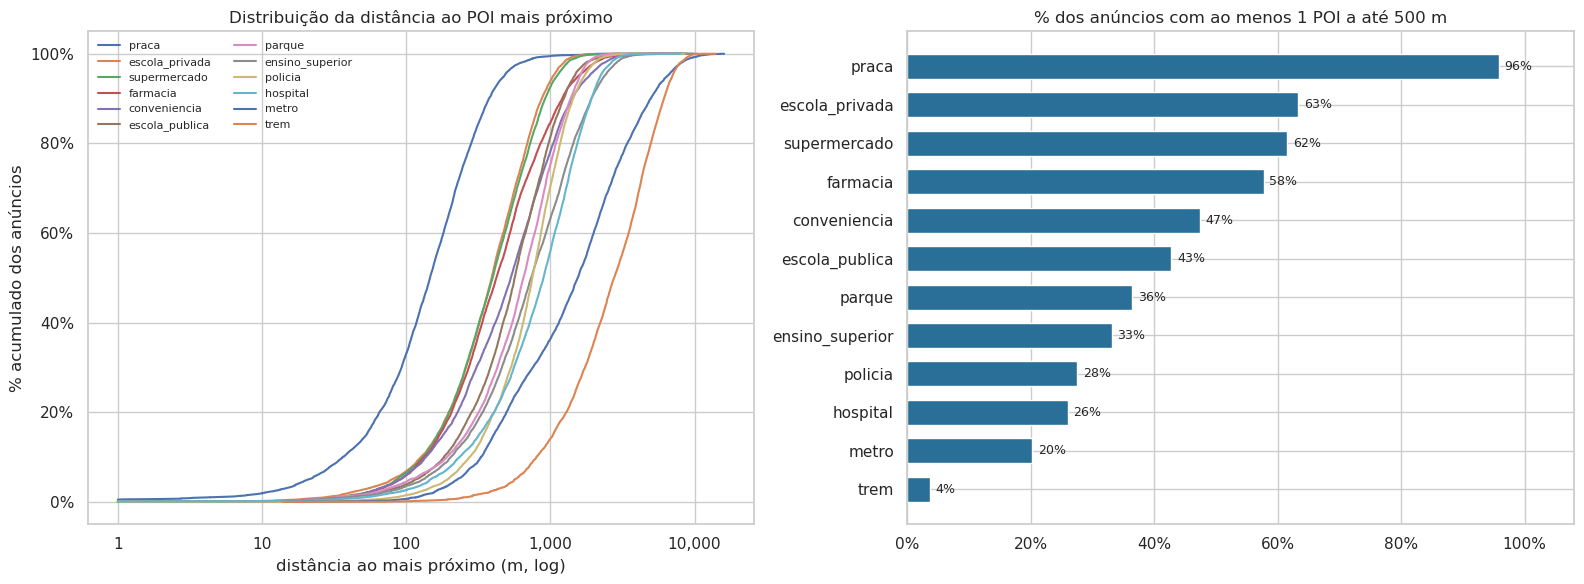

Distância mediana (m):
dist_praca               146.00
dist_escola_privada      391.00
dist_supermercado        398.00
dist_farmacia            421.00
dist_conveniencia        531.00
dist_escola_publica      565.00
dist_parque              649.00
dist_ensino_superior     735.00
dist_policia             748.00
dist_hospital            896.00
dist_metro             1,544.00
dist_trem              2,762.00


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ordem = df[DIST].median().sort_values().index
for col in ordem:
    x = np.sort(df[col].clip(lower=1))
    axes[0].plot(x, np.arange(1, len(x) + 1) / len(x), lw=1.5, label=col.replace("dist_", ""))
axes[0].set_xscale("log")
axes[0].xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
axes[0].set_xlabel("distância ao mais próximo (m, log)")
axes[0].set_ylabel("% acumulado dos anúncios")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].set_title("Distribuição da distância ao POI mais próximo")
axes[0].legend(fontsize=8, ncol=2, frameon=False)

cobertura = pd.Series({c: (df[f"dist_{c}"] <= 500).mean() for c in CATS}).sort_values()
axes[1].barh(cobertura.index, cobertura.values, color=COR, height=0.65)
for i, v in enumerate(cobertura.values):
    axes[1].annotate(f"{v:.0%}", (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[1].set_xlim(0, 1.08)
axes[1].set_title("% dos anúncios com ao menos 1 POI a até 500 m")
plt.tight_layout()
plt.show()

print("Distância mediana (m):")
print(df[DIST].median().sort_values().round(0).to_string())

## 6. R$/m² × distância a cada POI

Mediana de R$/m² por faixa de distância. Usamos **R$/m²** para neutralizar o tamanho do imóvel.
Faixas: 0–250, 250–500, 500–1.000, 1.000–2.000, > 2.000 m.

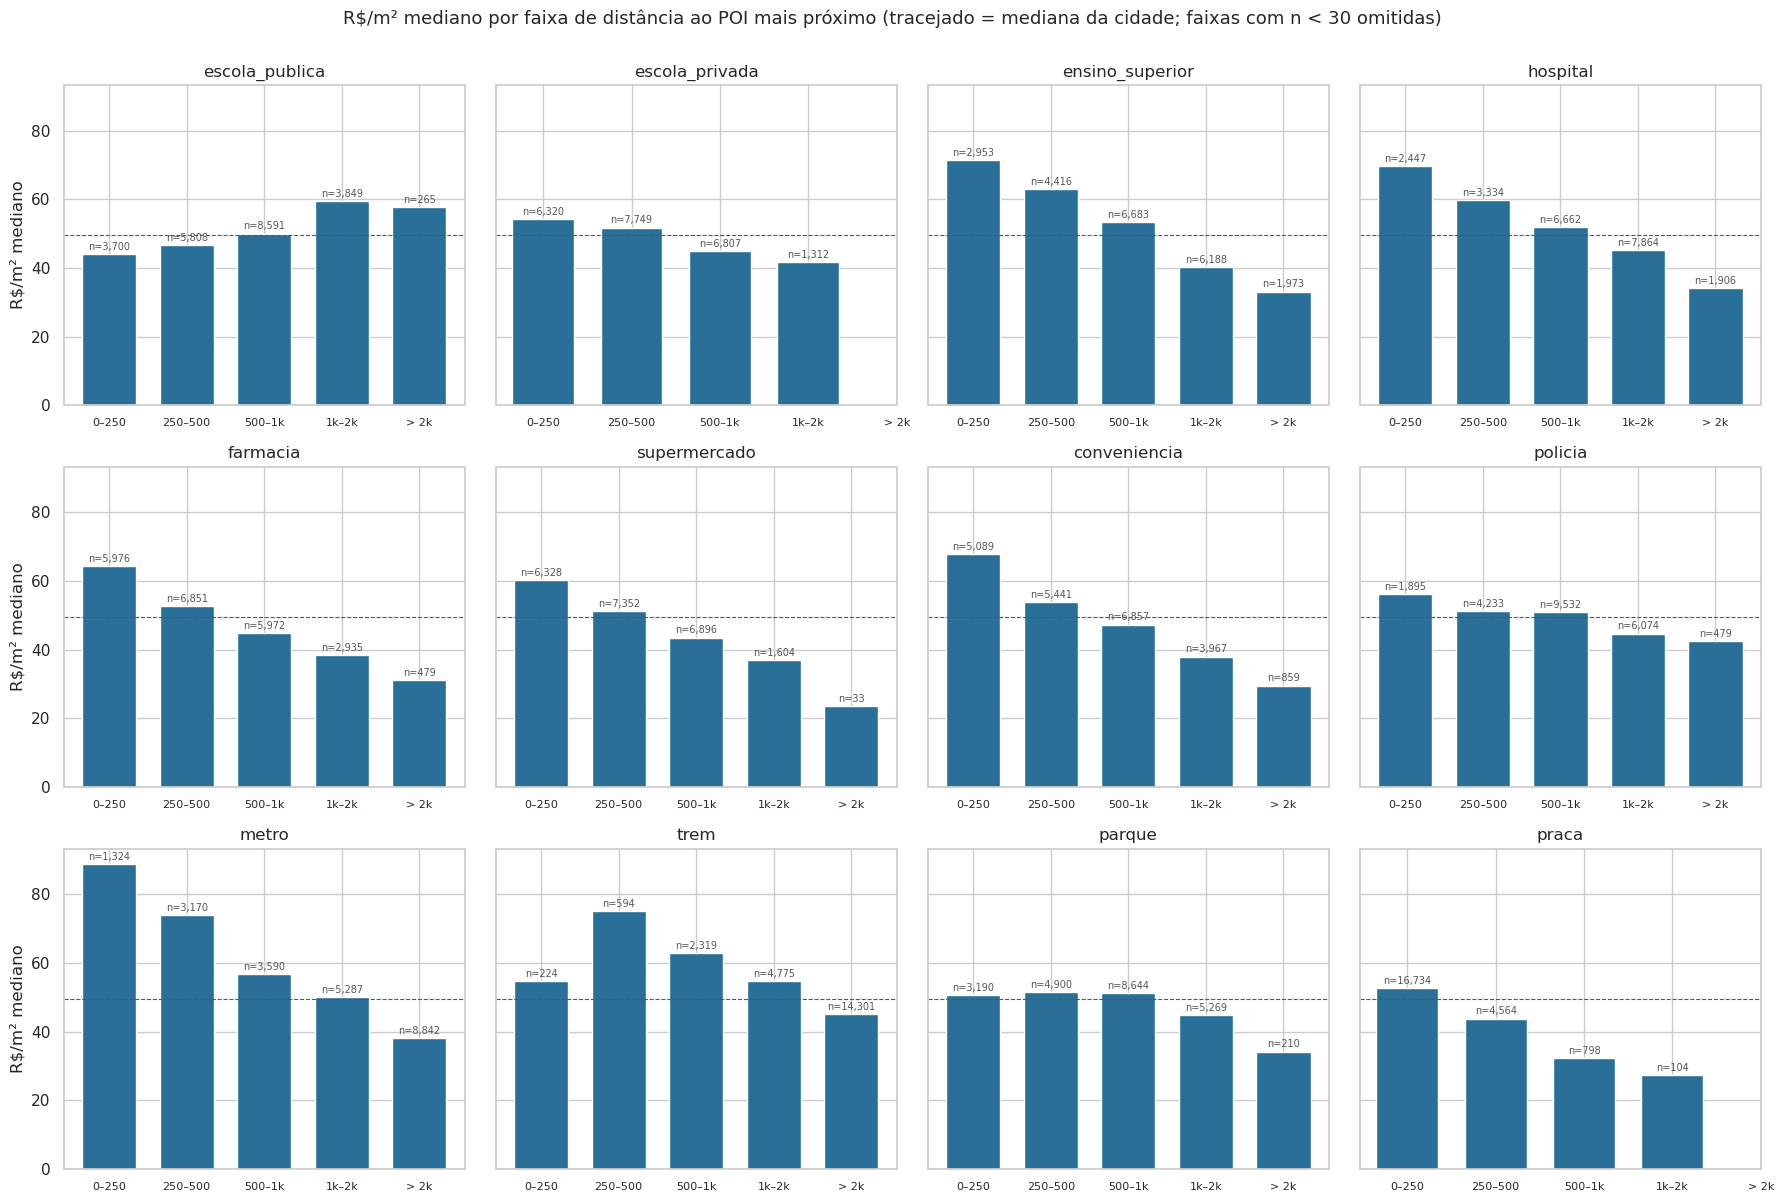

,0–250,250–500,500–1k,1k–2k,> 2k,perto/longe
escola_publica,43.90,46.60,50.00,59.50,57.70,-0.30
trem,54.60,75.00,63.00,54.80,45.10,0.10
parque,50.50,51.40,51.10,44.80,34.20,0.30
policia,56.20,51.20,50.90,44.70,42.60,0.30
escola_privada,54.30,51.70,45.00,41.70,NaN,0.30
hospital,69.70,59.70,51.80,45.30,34.20,0.80
farmacia,64.30,52.60,44.70,38.40,31.20,0.80
praca,52.80,43.80,32.20,27.30,NaN,0.90
ensino_superior,71.40,63.00,53.40,40.20,33.10,0.90
supermercado,60.30,51.30,43.60,36.90,23.50,1.00


In [18]:
FAIXAS = [0, 250, 500, 1000, 2000, np.inf]
ROT = ["0–250", "250–500", "500–1k", "1k–2k", "> 2k"]
mediana_geral = df["rent_m2"].median()

fig, axes = plt.subplots(3, 4, figsize=(18, 12), sharey=True)
curvas = {}
for ax, c in zip(axes.flat, CATS):
    faixa = pd.cut(df[f"dist_{c}"], FAIXAS, labels=ROT, right=False)
    g = df.groupby(faixa, observed=False)["rent_m2"].agg(mediana="median", n="size")
    g.loc[g["n"] < 30, "mediana"] = np.nan
    curvas[c] = g["mediana"]
    ax.bar(range(len(ROT)), g["mediana"], color=COR, width=0.7)
    ax.axhline(mediana_geral, color="#555", ls="--", lw=0.8)
    for i, (m, n) in enumerate(zip(g["mediana"], g["n"])):
        if pd.notna(m):
            ax.annotate(f"n={n:,}", (i, m), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7, color="#555")
    ax.set_xticks(range(len(ROT)), ROT, fontsize=8)
    ax.set_title(c)
for ax in axes[:, 0]:
    ax.set_ylabel("R$/m² mediano")
fig.suptitle("R$/m² mediano por faixa de distância ao POI mais próximo (tracejado = mediana da cidade; faixas com n < 30 omitidas)",
             y=1.0, fontsize=13)
plt.tight_layout()
plt.show()

perto_longe = pd.DataFrame(curvas).T
perto_longe["perto/longe"] = perto_longe["0–250"] / perto_longe[["1k–2k", "> 2k"]].mean(axis=1) - 1
perto_longe.sort_values("perto/longe").round(1)

### 6.1 Correlação de Spearman com R$/m²

Comparamos as três representações (distância, contagem em 1 km, acessibilidade) para ver qual carrega mais sinal.
Distância tem sinal invertido (mais perto = menor distância), então mostramos **−ρ** para distância.

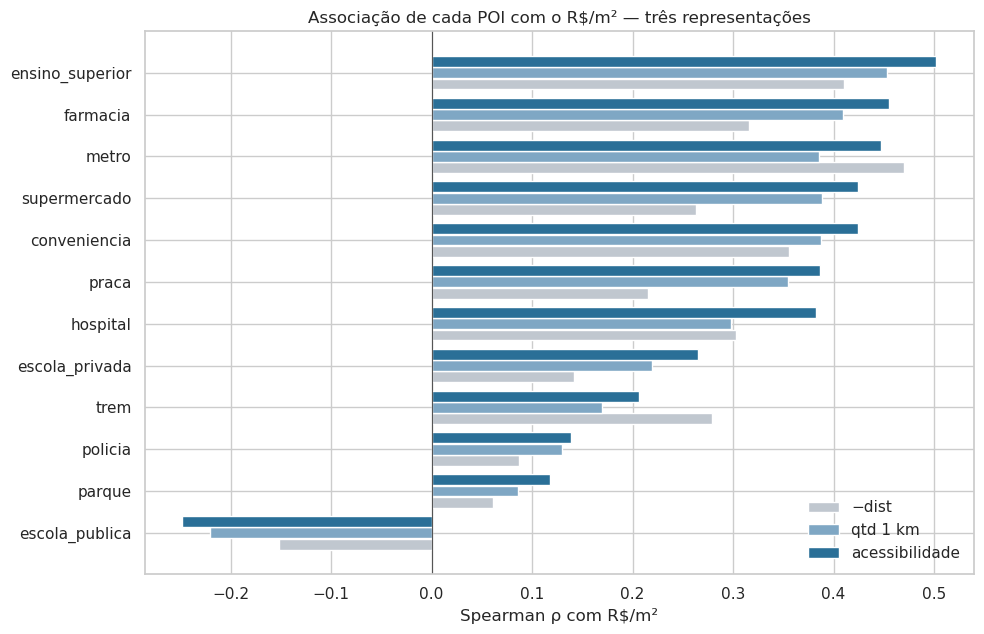

,−dist,qtd 1 km,acessibilidade
categoria,,,
escola_publica,-0.15,-0.22,-0.25
parque,0.06,0.09,0.12
policia,0.09,0.13,0.14
trem,0.28,0.17,0.21
escola_privada,0.14,0.22,0.27
hospital,0.30,0.30,0.38
praca,0.22,0.35,0.39
conveniencia,0.36,0.39,0.42
supermercado,0.26,0.39,0.42


In [19]:
linhas = []
for c in CATS:
    linhas.append({"categoria": c,
                   "−dist": -stats.spearmanr(df[f"dist_{c}"], df["rent_m2"])[0],
                   "qtd 1 km": stats.spearmanr(df[f"qtd_{c}_1km"], df["rent_m2"])[0],
                   "acessibilidade": stats.spearmanr(df[f"acess_{c}"], df["rent_m2"])[0]})
sp = pd.DataFrame(linhas).set_index("categoria").sort_values("acessibilidade")

fig, ax = plt.subplots(figsize=(10, 6.5))
y = np.arange(len(sp))
for (col, cor), off in zip({"−dist": "#c0c7cf", "qtd 1 km": "#7fa7c4", "acessibilidade": COR}.items(), [-0.27, 0, 0.27]):
    ax.barh(y + off, sp[col], height=0.26, color=cor, label=col)
ax.axvline(0, color="#555", lw=0.8)
ax.set_yticks(y, sp.index)
ax.set_xlabel("Spearman ρ com R$/m²")
ax.set_title("Associação de cada POI com o R$/m² — três representações")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()
sp.round(3)

## 7. POIs como retrato de "área nobre"

Se os POIs só refletem a localização, eles devem:
1. ser **muito correlacionados entre si** (áreas centrais têm de tudo);
2. ter uma **componente comum** que, sozinha, explica boa parte do R$/m².

Testamos isso com a matriz de correlação e uma **PCA** das acessibilidades.

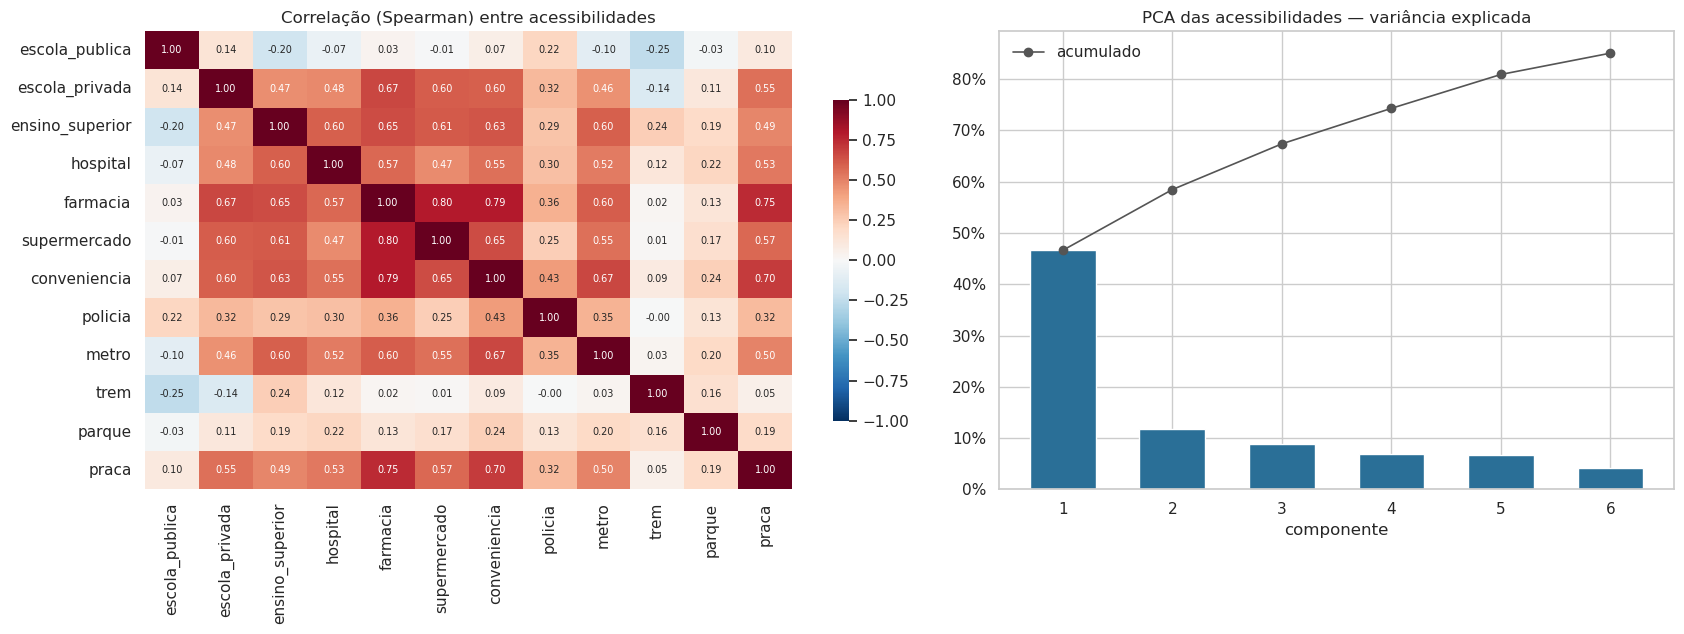

PC1 explica 47% da variância das 12 acessibilidades.
Spearman PC1 × R$/m²: ρ = 0.51

Cargas da PC1:
escola_publica    -0.00
trem               0.01
parque             0.12
policia            0.23
escola_privada     0.31
praca              0.32
hospital           0.32
metro              0.33
ensino_superior    0.33
supermercado       0.35
conveniencia       0.38
farmacia           0.38


In [20]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

corr = df[ACESS].corr(method="spearman")
corr.index = corr.columns = [c.replace("acess_", "") for c in ACESS]

Z = StandardScaler().fit_transform(np.log1p(df[ACESS]))
pca = PCA(random_state=RNG).fit(Z)
df["poi_pc1"] = pca.transform(Z)[:, 0]
if stats.spearmanr(df["poi_pc1"], df["acess_metro"])[0] < 0:   # orienta: maior = mais infraestrutura
    df["poi_pc1"] *= -1

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
            ax=axes[0], cbar_kws={"shrink": 0.7})
axes[0].set_title("Correlação (Spearman) entre acessibilidades")

var = pca.explained_variance_ratio_[:6]
axes[1].bar(range(1, len(var) + 1), var, color=COR, width=0.6)
axes[1].plot(range(1, len(var) + 1), np.cumsum(var), color="#555", marker="o", lw=1.2, label="acumulado")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[1].set_xlabel("componente")
axes[1].set_title("PCA das acessibilidades — variância explicada")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

carga = pd.Series(pca.components_[0], index=corr.index).sort_values()
rho_pc1, _ = stats.spearmanr(df["poi_pc1"], df["rent_m2"])
print(f"PC1 explica {var[0]:.0%} da variância das 12 acessibilidades.")
print(f"Spearman PC1 × R$/m²: ρ = {rho_pc1:.2f}")
print("\nCargas da PC1:")
print(carga.round(2).to_string())

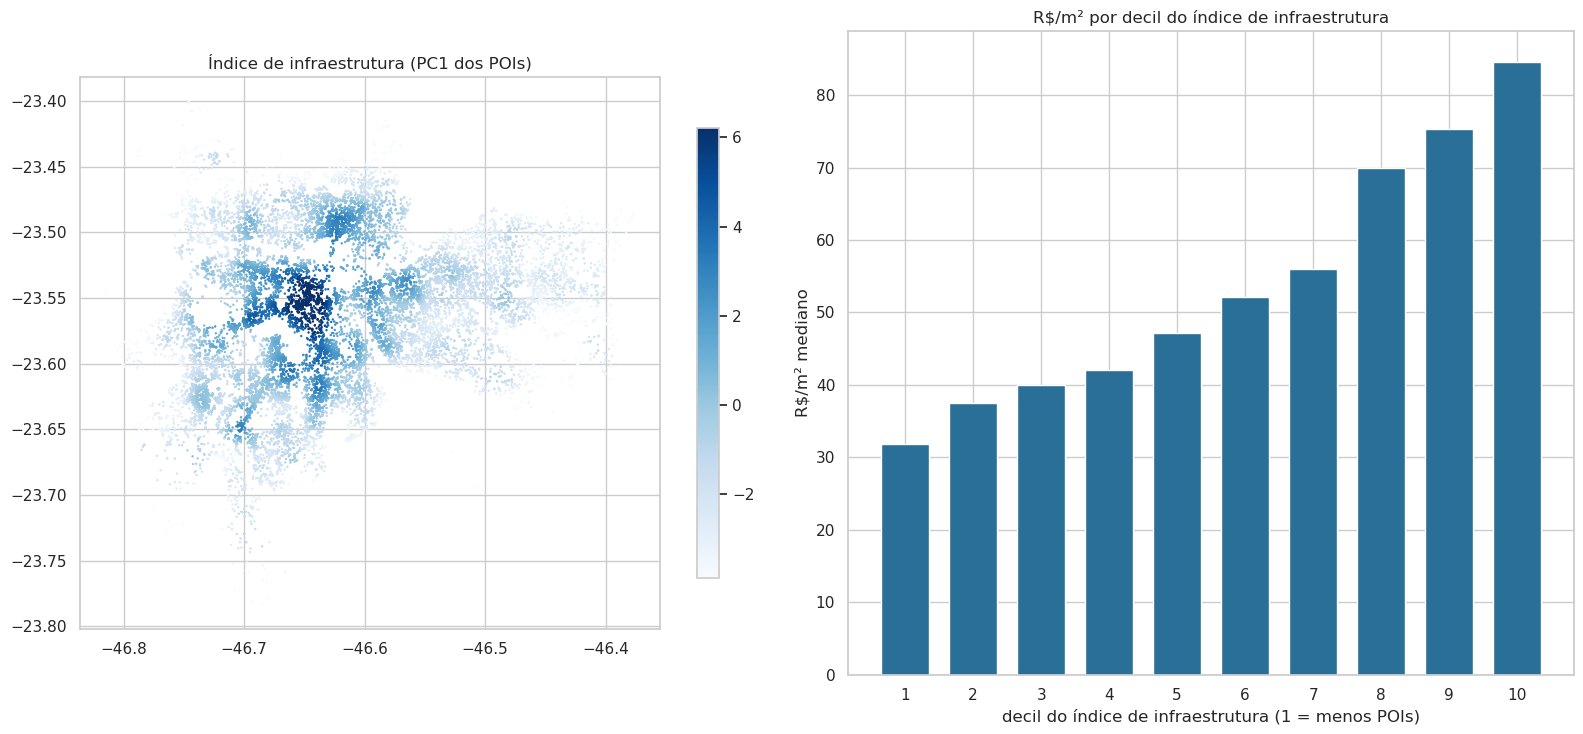

Decil 10 / decil 1: 2.7x


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
lim = df["poi_pc1"].quantile([0.02, 0.98])
sc = axes[0].scatter(df["lon"], df["lat"], c=df["poi_pc1"].clip(*lim), cmap="Blues", s=3, linewidths=0)
axes[0].set_aspect(1 / np.cos(np.radians(-23.55)))
axes[0].set_title("Índice de infraestrutura (PC1 dos POIs)")
fig.colorbar(sc, ax=axes[0], shrink=0.7)

dec = pd.qcut(df["poi_pc1"], 10, labels=range(1, 11))
g = df.groupby(dec, observed=True)["rent_m2"].median()
axes[1].bar(g.index.astype(int), g.values, color=COR, width=0.7)
axes[1].set_xticks(range(1, 11))
axes[1].set_xlabel("decil do índice de infraestrutura (1 = menos POIs)")
axes[1].set_ylabel("R$/m² mediano")
axes[1].set_title("R$/m² por decil do índice de infraestrutura")
plt.tight_layout()
plt.show()
print(f"Decil 10 / decil 1: {g.iloc[-1] / g.iloc[0]:.1f}x")

## 8. Escolas públicas × privadas

No projeto de compra: perto de escola pública → preço menor; perto de privada → maior.
Aqui olhamos o **mix escolar** a até 1 km: `% privadas = privadas / (privadas + públicas)`. Hipótese: o mix é um termômetro de renda do entorno.

Anúncios sem nenhuma escola (OSM) a 1 km: 1.7%


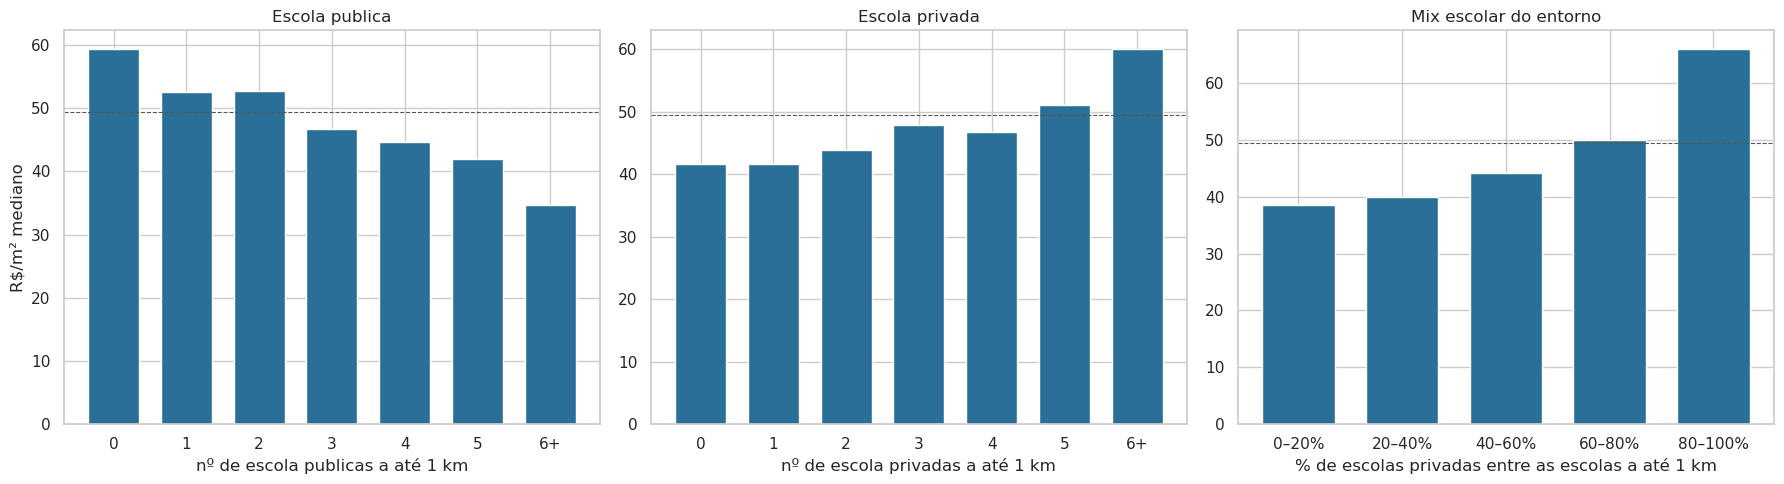

Spearman % privadas × R$/m²: ρ = 0.31
                        mediana     n
pct_escola_privada_1km               
0–20%                     38.50  1355
20–40%                    40.00  2529
40–60%                    44.10  5349
60–80%                    50.00  5924
80–100%                   66.00  6677


In [22]:
tot = df["qtd_escola_privada_1km"] + df["qtd_escola_publica_1km"]
df["pct_escola_privada_1km"] = np.where(tot > 0, df["qtd_escola_privada_1km"] / tot.replace(0, 1), np.nan)
print(f"Anúncios sem nenhuma escola (OSM) a 1 km: {(tot == 0).mean():.1%}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, c in zip(axes[:2], ["escola_publica", "escola_privada"]):
    q = df[f"qtd_{c}_1km"].clip(upper=6)
    g = df.groupby(q)["rent_m2"].agg(mediana="median", n="size").query("n >= 30")
    ax.bar(g.index, g["mediana"], color=COR, width=0.7)
    ax.axhline(mediana_geral, color="#555", ls="--", lw=0.8)
    ax.set_xticks(g.index, [f"{int(i)}" if i < 6 else "6+" for i in g.index])
    ax.set_xlabel(f"nº de {c.replace('_', ' ')}s a até 1 km")
    ax.set_title(c.replace("_", " ").capitalize())
axes[0].set_ylabel("R$/m² mediano")

mix = pd.cut(df["pct_escola_privada_1km"], [-0.01, 0.2, 0.4, 0.6, 0.8, 1.0], labels=["0–20%", "20–40%", "40–60%", "60–80%", "80–100%"])
g = df.groupby(mix, observed=True)["rent_m2"].agg(mediana="median", n="size")
axes[2].bar(range(len(g)), g["mediana"], color=COR, width=0.7)
axes[2].axhline(mediana_geral, color="#555", ls="--", lw=0.8)
axes[2].set_xticks(range(len(g)), g.index)
axes[2].set_xlabel("% de escolas privadas entre as escolas a até 1 km")
axes[2].set_title("Mix escolar do entorno")
plt.tight_layout()
plt.show()

rho_mix, p_mix = stats.spearmanr(df["pct_escola_privada_1km"], df["rent_m2"], nan_policy="omit")
print(f"Spearman % privadas × R$/m²: ρ = {rho_mix:.2f}")
print(g.round(1).to_string())

## 9. Metrô e trem

1. O R$/m² cai com a distância à estação? Metrô e trem se comportam igual?
2. A flag do anúncio `inst_perto_de_metro_ou_trem` (preenchida pelo anunciante) bate com a distância real?

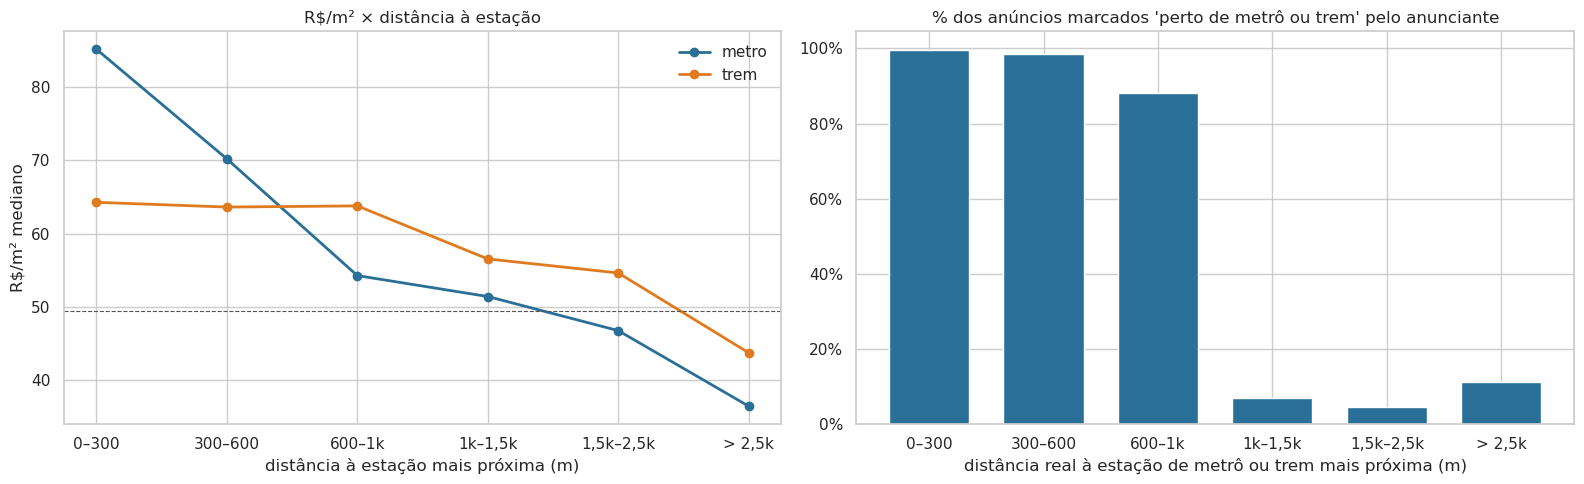

0–300        100%
300–600       98%
600–1k        88%
1k–1,5k        7%
1,5k–2,5k      5%
> 2,5k        11%


In [23]:
bins = [0, 300, 600, 1000, 1500, 2500, np.inf]
rot = ["0–300", "300–600", "600–1k", "1k–1,5k", "1,5k–2,5k", "> 2,5k"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for c, cor in [("metro", COR), ("trem", "#e07a1f")]:
    faixa = pd.cut(df[f"dist_{c}"], bins, labels=rot, right=False)
    g = df.groupby(faixa, observed=False)["rent_m2"].agg(mediana="median", n="size")
    g.loc[g["n"] < 30, "mediana"] = np.nan
    axes[0].plot(rot, g["mediana"], marker="o", lw=2, color=cor, label=c)
axes[0].axhline(mediana_geral, color="#555", ls="--", lw=0.8)
axes[0].set_xlabel("distância à estação mais próxima (m)")
axes[0].set_ylabel("R$/m² mediano")
axes[0].set_title("R$/m² × distância à estação")
axes[0].legend(frameon=False)

dist_tp = df[["dist_metro", "dist_trem"]].min(axis=1)
faixa = pd.cut(dist_tp, bins, labels=rot, right=False)
flag = df.groupby(faixa, observed=False)["inst_perto_de_metro_ou_trem"].mean()
axes[1].bar(range(len(flag)), flag.values, color=COR, width=0.7)
axes[1].set_xticks(range(len(flag)), rot)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[1].set_xlabel("distância real à estação de metrô ou trem mais próxima (m)")
axes[1].set_title("% dos anúncios marcados 'perto de metrô ou trem' pelo anunciante")
plt.tight_layout()
plt.show()

print(flag.map("{:.0%}".format).to_string())

> **Leitura:** a flag é praticamente a regra "estação a até ~1 km" (≈ 100% até 600 m, ≈ 88% entre 600 m e 1 km, < 12% acima disso) — ou seja, é **calculada pelo portal**, não declarada pelo anunciante.
> A distância real carrega a mesma informação **e** o gradiente (300 m vale mais que 900 m), então ela substitui a flag no modelo.

## 10. Resumo e hipóteses para o 04

### O que a EDA mostra

**1. Quase todo POI se associa a aluguel mais caro — exceto escola pública.**
- Associação mais forte com R$/m² (Spearman da acessibilidade): ensino superior 0,50, farmácia 0,46, metrô 0,45, supermercado e conveniência 0,42, hospital 0,38.
- Metrô: 89 R$/m² a até 250 m da estação contra 38 R$/m² a mais de 2 km.
- **Escola pública é o único POI com sinal negativo** (ρ = −0,25): R$/m² de 44 a até 250 m contra 60 entre 1 e 2 km. Escola privada vai no sentido oposto (ρ = +0,27).
- O **mix escolar** separa bem o entorno: onde 80–100% das escolas próximas são privadas, o R$/m² mediano é 66; onde são 0–20%, é 38.
- Polícia (0,14) e parque grande (0,12) quase não se associam ao preço.

**2. Os POIs contam, em boa parte, a mesma história: "área central e consolidada".**
- Uma única componente (PC1) resume 47% da variação das 12 acessibilidades. Carregam nela comércio, saúde, ensino superior e metrô — escola pública e trem ficam de fora (medem outra coisa).
- O R$/m² no decil mais "equipado" é 2,7× o do decil menos equipado.

**3. O OSM é mais completo onde o aluguel é mais caro.**
- A densidade de POIs mapeados por região tem ρ = 0,68 com o R$/m² da região.
- O OSM tem só 649 escolas públicas na capital, quando a rede real tem milhares.
- Parte do "efeito POI" é, portanto, **efeito de mapeamento + renda**. Por isso o 04 compara imóveis **dentro da mesma região**.

**4. Metrô e trem se comportam diferente.**
- Metrô: queda contínua do R$/m² com a distância.
- Trem: o R$/m² colado à estação (0–250 m) é menor que a 250–500 m — possível efeito de ruído / barreira da linha.
- A flag `inst_perto_de_metro_ou_trem` do anúncio equivale a "estação a até ~1 km"; a distância real a substitui com mais informação.

### Hipóteses para o 04
| # | Hipótese |
|---|---|
| P1 | Perto de escola pública o aluguel é menor, mesmo dentro da região |
| P2 | Perto de escola privada o aluguel é maior, mesmo dentro da região |
| P3 | O mix escolar mede renda do entorno |
| P4 | O prêmio do metrô decai com a distância; metrô vale mais que trem |
| P5 | Morar colado à linha de trem (< 300 m) tem desconto |
| P6 | Comércio e saúde perdem quase todo o efeito ao controlar a região |
| P7 | Parque grande valoriza dentro da região |
| P8 | POIs substituem a região na previsão e generalizam melhor para áreas não vistas |
| P9 | POIs reduzem a autocorrelação espacial dos resíduos |

## 11. Salvar

In [24]:
df = df.drop(columns=["n_pois_1km"])
df.to_parquet(OUT_POI, index=False)
print(f"{OUT_POI.relative_to(ROOT)} -> {df.shape}")
print("Colunas novas:", [c for c in df.columns if c.startswith(("dist_", "qtd_", "acess_", "poi_", "pct_escola"))][:6], "...")

data/interim/aluguel_sp_poi.parquet -> (22213, 146)
Colunas novas: ['dist_centro_km', 'dist_escola_publica', 'qtd_escola_publica_500m', 'qtd_escola_publica_1km', 'acess_escola_publica', 'dist_escola_privada'] ...
